<a href="https://colab.research.google.com/github/kiethaxxelcortez-bit/Cortez_Knn-Activity/blob/main/Cortez_Keith_KNN_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I. Activity Objectives

1. K-Nearest Neighbors (KNN) is a supervised machine learning algorithm that makes predictions based on the closest data points to a given input. In classification, KNN assigns the class that appears most frequently among the nearest neighbors. In regression, it predicts a numerical value by calculating the average of the target values of the nearest neighbors.

2. The nearest-neighbor visualization shows the data points closest to the sample being predicted. Decision boundaries show the regions where the model predicts different classes. Regression curves illustrate the relationship between input features and predicted numerical values. Evaluation metrics, such as accuracy for classification and mean squared error (MSE) for regression, help determine how well the model performs.

3. Changing the value of K affects how KNN makes predictions. A small K value makes the model more sensitive to nearby data points and noise, which may lead to overfitting. A larger K value produces smoother predictions but may overlook important patterns, leading to underfitting. The best K value depends on the dataset and should be selected through experimentation.

4. Dataset characteristics such as the number of samples, overlapping classes, noise, feature scaling, and class imbalance can affect KNN performance. When classes are clearly separated, KNN generally performs better. When classes overlap or contain noisy data, classification errors may increase. Feature scaling is important because KNN relies on distance calculations.

5. The results can be explained by comparing the model's predictions, decision boundaries, and evaluation metrics for different K values. For example, if a smaller K produces irregular decision boundaries and lower test accuracy, the model may be overfitting. If a larger K produces smoother boundaries but misclassifies several data points, it may be underfitting. These observations help identify which K value works best for the dataset.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error


np.random.seed(42)

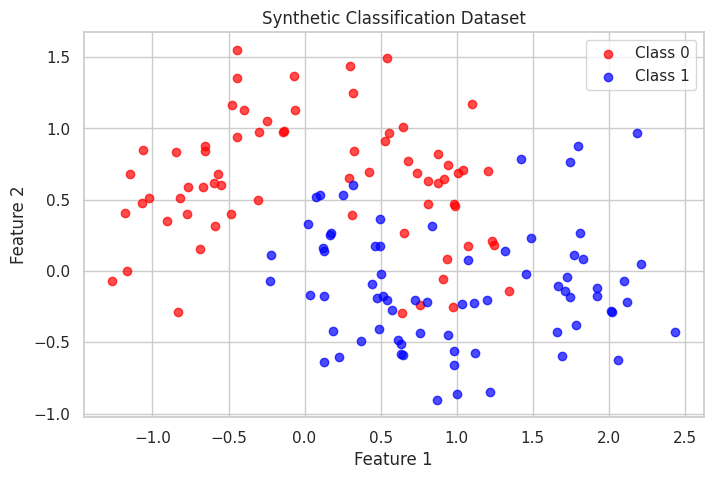

In [ ]:

X_clf, y_clf = make_moons(n_samples=200, noise=0.3, random_state=42)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.3, random_state=42)


plt.figure(figsize=(8, 5))
plt.scatter(X_train_c[y_train_c == 0, 0], X_train_c[y_train_c == 0, 1], color='red', label='Class 0', alpha=0.7)
plt.scatter(X_train_c[y_train_c == 1, 0], X_train_c[y_train_c == 1, 1], color='blue', label='Class 1', alpha=0.7)
plt.title("Synthetic Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

k_clf = 5
clf = KNeighborsClassifier(n_neighbors=k_clf, weights='uniform')
clf.fit(X_train_c, y_train_c)


y_pred_c = clf.predict(X_test_c)
accuracy = accuracy_score(y_test_c, y_pred_c)
print(f"KNN Classifier (k={k_clf}) Accuracy: {accuracy:.4f}")

KNN Classifier (k=5) Accuracy: 0.9167


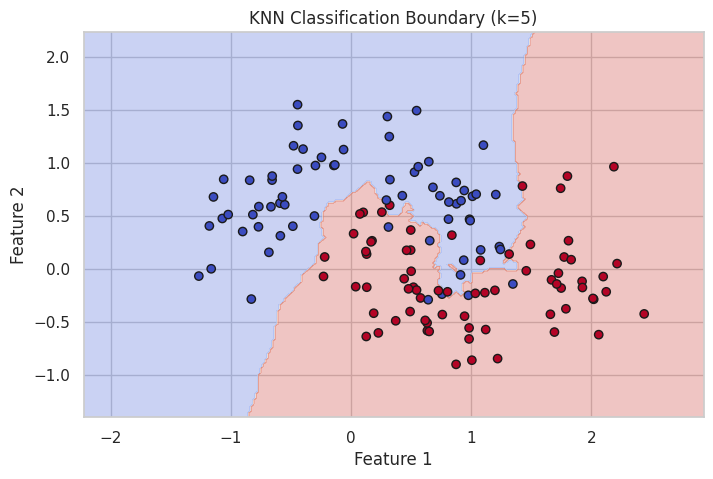

In [ ]:

x_min, x_max = X_clf[:, 0].min() - 0.5, X_clf[:, 0].max() + 0.5
y_min, y_max = X_clf[:, 1].min() - 0.5, X_clf[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_train_c[:, 0], X_train_c[:, 1], c=y_train_c, cmap=plt.cm.coolwarm, edgecolors='k')
plt.title(f"KNN Classification Boundary (k={k_clf})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()

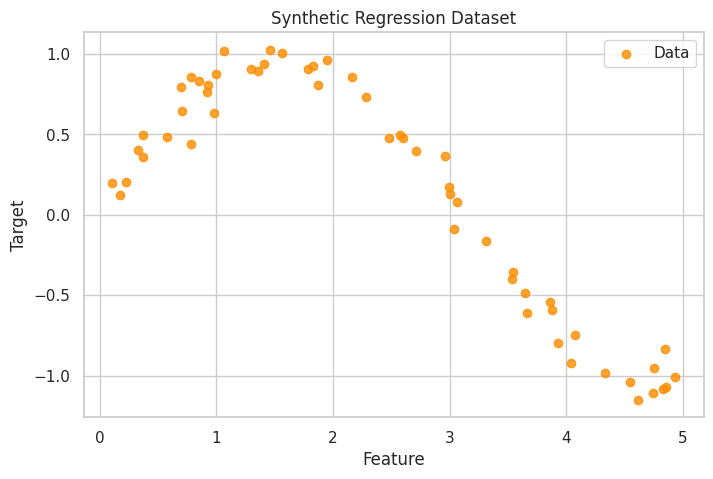

In [ ]:

X_reg = np.sort(5 * np.random.rand(80, 1), axis=0)
y_reg = np.sin(X_reg).ravel() + np.random.normal(0, 0.1, X_reg.shape[0])

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)


plt.figure(figsize=(8, 5))
plt.scatter(X_train_r, y_train_r, color='darkorange', label='Data', alpha=0.8)
plt.title("Synthetic Regression Dataset")
plt.xlabel("Feature")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

k_reg = 5
reg = KNeighborsRegressor(n_neighbors=k_reg, weights='uniform')
reg.fit(X_train_r, y_train_r)


y_pred_r = reg.predict(X_test_r)
mse = mean_squared_error(y_test_r, y_pred_r)
print(f"KNN Regressor (k={k_reg}) MSE: {mse:.4f}")

KNN Regressor (k=5) MSE: 0.0164


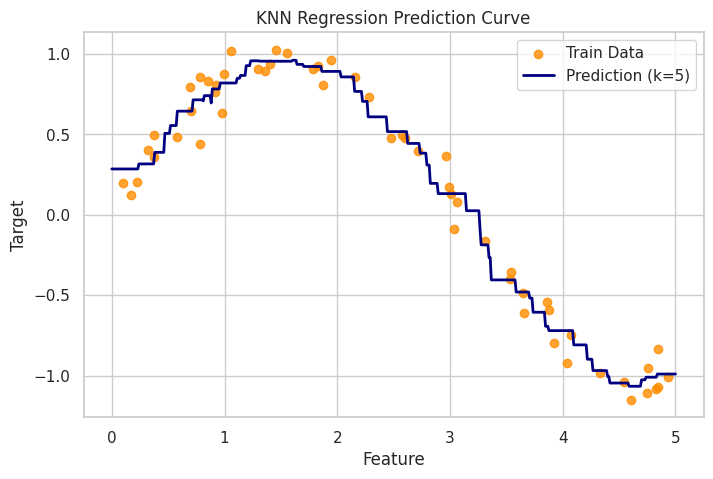

In [ ]:

T = np.linspace(0, 5, 500)[:, np.newaxis]
y_pred_line = reg.predict(T)

plt.figure(figsize=(8, 5))
plt.scatter(X_train_r, y_train_r, color='darkorange', label='Train Data', alpha=0.8)
plt.plot(T, y_pred_line, color='navy', label=f'Prediction (k={k_reg})', linewidth=2)
plt.title("KNN Regression Prediction Curve")
plt.xlabel("Feature")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for k in [3, 9]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_c, y_train_c)
    acc = accuracy_score(y_test_c, model.predict(X_test_c))
    print(f"KNN Classification (k={k}) Accuracy: {acc:.4f}")

KNN Classification (k=3) Accuracy: 0.8833
KNN Classification (k=9) Accuracy: 0.9167


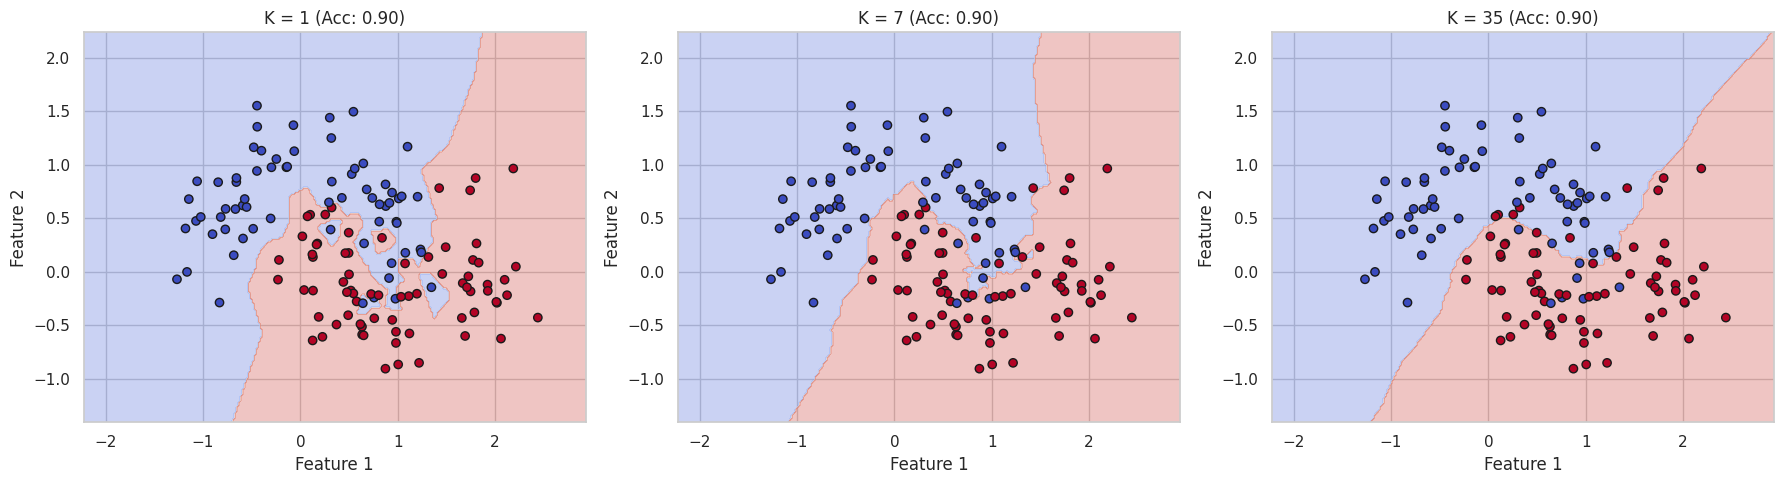

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, [1, 7, 35]):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_c, y_train_c)

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    ax.scatter(X_train_c[:, 0], X_train_c[:, 1], c=y_train_c, cmap=plt.cm.coolwarm, edgecolors='k')
    ax.set_title(f"K = {k} (Acc: {accuracy_score(y_test_c, model.predict(X_test_c)):.2f})")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

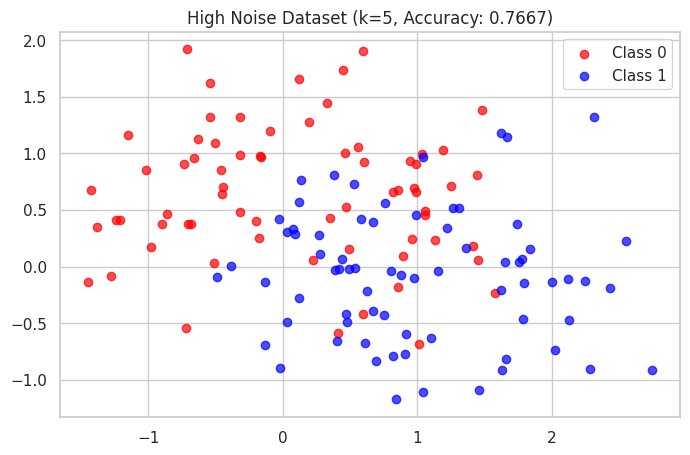

In [ ]:
# Generate noisier classification dataset
X_noisy, y_noisy = make_moons(n_samples=200, noise=0.5, random_state=42)
X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(X_noisy, y_noisy, test_size=0.3, random_state=42)

# Train KNN Classifier on noisy dataset
clf_noisy = KNeighborsClassifier(n_neighbors=5)
clf_noisy.fit(X_train_n, y_train_n)
noisy_acc = accuracy_score(y_test_n, clf_noisy.predict(X_test_n))

plt.figure(figsize=(8, 5))
plt.scatter(X_train_n[y_train_n == 0, 0], X_train_n[y_train_n == 0, 1], color='red', label='Class 0', alpha=0.7)
plt.scatter(X_train_n[y_train_n == 1, 0], X_train_n[y_train_n == 1, 1], color='blue', label='Class 1', alpha=0.7)
plt.title(f"High Noise Dataset (k=5, Accuracy: {noisy_acc:.4f})")
plt.legend()
plt.grid(True)
plt.show()

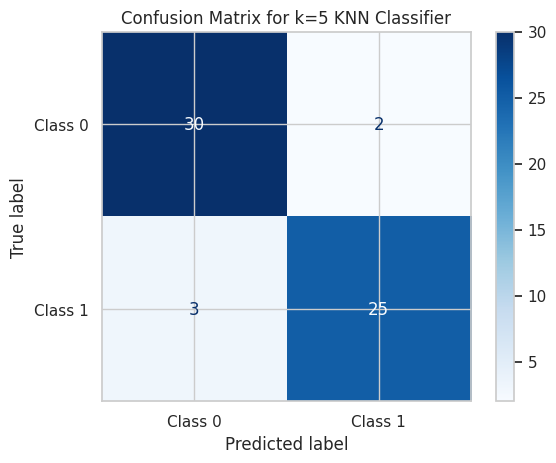

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_c, y_train_c)
y_pred = model.predict(X_test_c)

cm = confusion_matrix(y_test_c, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for k=5 KNN Classifier")
plt.show()

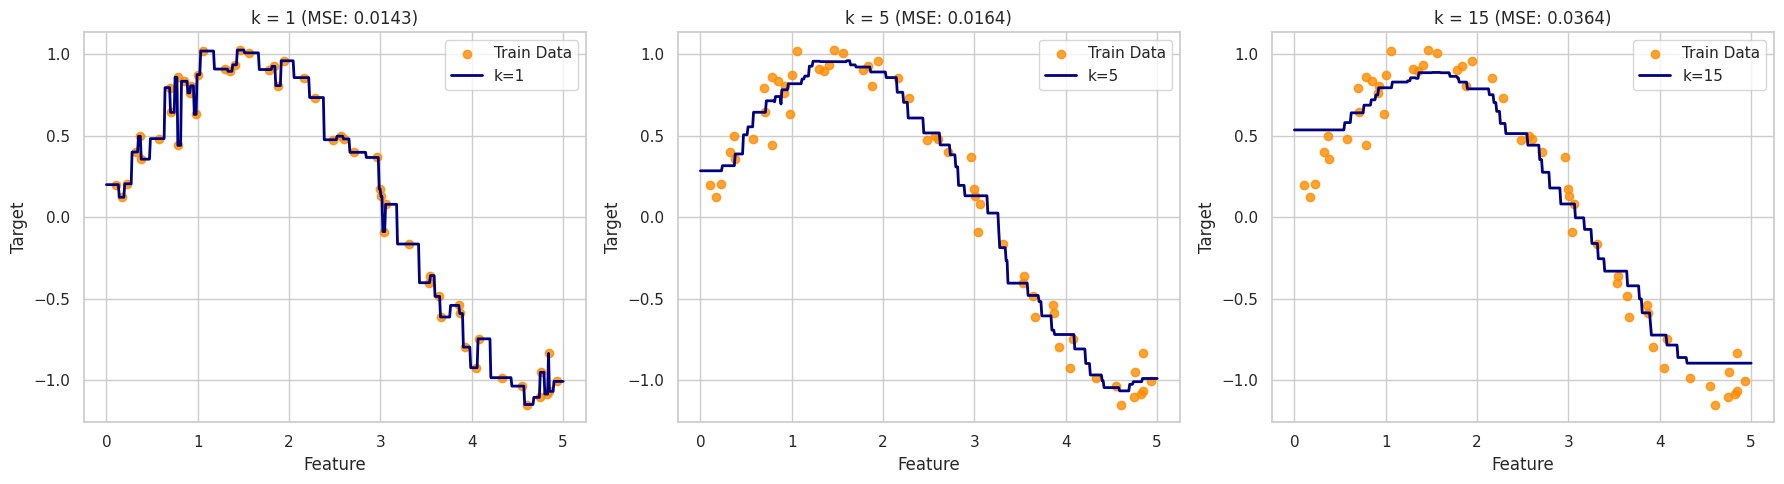

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
T_smooth = np.linspace(0, 5, 500)[:, np.newaxis]

for ax, k in zip(axes, [1, 5, 15]):
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_r, y_train_r)
    y_smooth_pred = model.predict(T_smooth)
    test_mse = mean_squared_error(y_test_r, model.predict(X_test_r))

    ax.scatter(X_train_r, y_train_r, color='darkorange', label='Train Data', alpha=0.8)
    ax.plot(T_smooth, y_smooth_pred, color='navy', linewidth=2, label=f'k={k}')
    ax.set_title(f"k = {k} (MSE: {test_mse:.4f})")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Target")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()